# 🏁 Lekcja 9 (Finał): Wielki Turniej Modeli — Drzewo Decyzyjne vs Las Losowy vs Gradient Boosting oraz Twoja Mapa Drogowa na Kaggle!

Dotarliśmy do wielkiego finału naszego kursu! Przeszliśmy drogę od pierwszego wczytania pliku CSV, przez logarytmy, wykrywanie anomalii, łatanie dziur `NaN`, kodowanie tekstu (*Ordinal* i *One-Hot*), walidację krzyżową (*5-Fold CV*), aż po własnoręczne tworzenie nowych cech (*Feature Engineering*).

Przez cały ten czas używaliśmy jednego silnika: **Lasu Losowego (`RandomForestRegressor`)**.  
Dziś postawimy na tej samej linii startowej (na naszych 16 przygotowanych cechach) **3 różne algorytmy Machine Learningu**, żeby zobaczyć, jak bardzo różni się ich sposób „myślenia”!

---

### 🧠 Jak myślą nasze 3 modele? (Analogia Biura Rzeczoznawców + Matematyka pod maską)

| Algorytm | Życiowa analogia | Jak działa matematyka pod maską? | Główna zaleta / wada |
| :--- | :--- | :--- | :--- |
| **1. 🌳 Drzewo Decyzyjne** *(`DecisionTreeRegressor`)* | **„Samotny Strzelec”** — jeden rzeczoznawca zamknięty w pokoju. | Buduje jedno ogromne, bardzo głębokie drzewo pytań (nawet 20 pięter w dół!), dopóki nie nauczy się na pamięć każdego pojedynczego domu ze zbioru treningowego. | ❌ **Wkuwa dane na blachę (*Overfitting*)** — gdy zobaczy nowy dom z sejfu, łatwo wpada w pułapkę i mocno się myli. |
| **2. 🌲🌲 Las Losowy** *(`RandomForestRegressor` — technika **Bagging**)* | **„Demokratyczny Parlament 100 Rzeczoznawców”** — każdy pracuje **równolegle** w osobnym pokoju (nie widzą pracy kolegów!). | Buduje 100 niezależnych, głębokich drzew na losowych wycinkach danych. Na końcu każde drzewo podaje swoją cenę, a komputer liczy **zwykłą średnią arytmetyczną**:<br>$$\text{Cena} = \frac{\text{Drzewo}_1 + \text{Drzewo}_2 + \dots + \text{Drzewo}_{100}}{100}$$ | ✅ Bardzo stabilny i odporny na błędy pojedynczych drzew, ale ponieważ drzewa nie rozmawiają ze sobą, każde popełnia podobne drobne niedokładności. |
| **3. 🚀 Gradient Boosting** *(`GradientBoostingRegressor` — technika **Boosting**)* | **„Sztafeta 100 Chirurgów”** — pracują **po kolei (jeden po drugim)**! Każdy kolejny specjalista patrzy na rachunek poprzednika i **poprawia tylko jego błąd**! | Zamiast uśredniać niezależne drzewa, tutaj **każde kolejne małe drzewko uczy się przewidywać POMYŁKĘ (tzw. resztę / *residual*) poprzednich drzew** i dodaje małą poprawkę:<br>$$\text{Cena} = \text{Start} + 0.1 \cdot \text{Poprawka}_1 + 0.1 \cdot \text{Poprawka}_2 + \dots$$ | 🏆 **Król danych tabelarycznych na Kaggle!** (Na tym samym pomyśle opierają się słynne biblioteki **XGBoost**, **LightGBM** oraz **CatBoost**). |

---

#### 🔬 Jak dokładnie działa sztafeta *Gradient Boosting* na konkretnym domu za `250 000 $`?

Zobaczmy krok po kroku na prostych liczbach, dlaczego **uczenie się na błędach poprzednika** działa tak genialnie:

| Krok sztafety | Aktualna wycena przed krokiem | Prawdziwa cena domu | Ile wynosi brakująca reszta (Błąd do naprawienia)? | Co robi kolejne drzewko w sztafecie? (Krok z ostrożnością `learning_rate = 0.1`) |
| :--- | :---: | :---: | :---: | :--- |
| **Start (Punkt wyjścia)** | **`180 000 $`** *(średnia wszystkich domów)* | `250 000 $` | Brakuje **`+70 000 $`** | **Drzewko nr 1** patrzy na cechy domu i widzi: *„Ten dom jest niedoszacowany o ok. $+70\,000\ \$$”*. Ale żeby nie przestrzelić, dokładamy do wyceny tylko **10% (`0.1`)** tej poprawki, czyli **`+7 000 $`**! |
| **Po Drzewku nr 1** | **`187 000 $`** *(180 tys. + 7 tys.)* | `250 000 $` | Brakuje już tylko **`+63 000 $`** | **Drzewko nr 2** uczy się na nowej reszcie (`+63 000 $`) i znów dokłada ostrożne 10% poprawki (**`+6 300 $`**)! |
| **Po Drzewku nr 2** | **`193 300 $`** *(187 tys. + 6.3 tys.)* | `250 000 $` | Brakuje **`+56 700 $`** | **Drzewko nr 3** znów koryguje pozostały błąd... |
| **...Po 100 Drzewkach!** | **`~249 200 $`** | `250 000 $` | Błąd bliski **zera**! | Po 100 drobnych korektach sztafeta dociera niemal w sam środek tarczy! |

Sprawdźmy to w kodzie i zobaczmy wynik naszego Wielkiego Turnieju!

=== 🏆 WYNIKI WIELKIEGO TURNIEJU MODELI (5-FOLD CROSS-VALIDATION) ===
1. Pojedyncze Drzewo (Decision Tree)          -> Średni błąd MAE: 24,594 $
2. Las Losowy — 100 drzew (Random Forest)     -> Średni błąd MAE: 16,960 $
3. Sztafeta — 100 drzew (Gradient Boosting)   -> Średni błąd MAE: 16,120 $


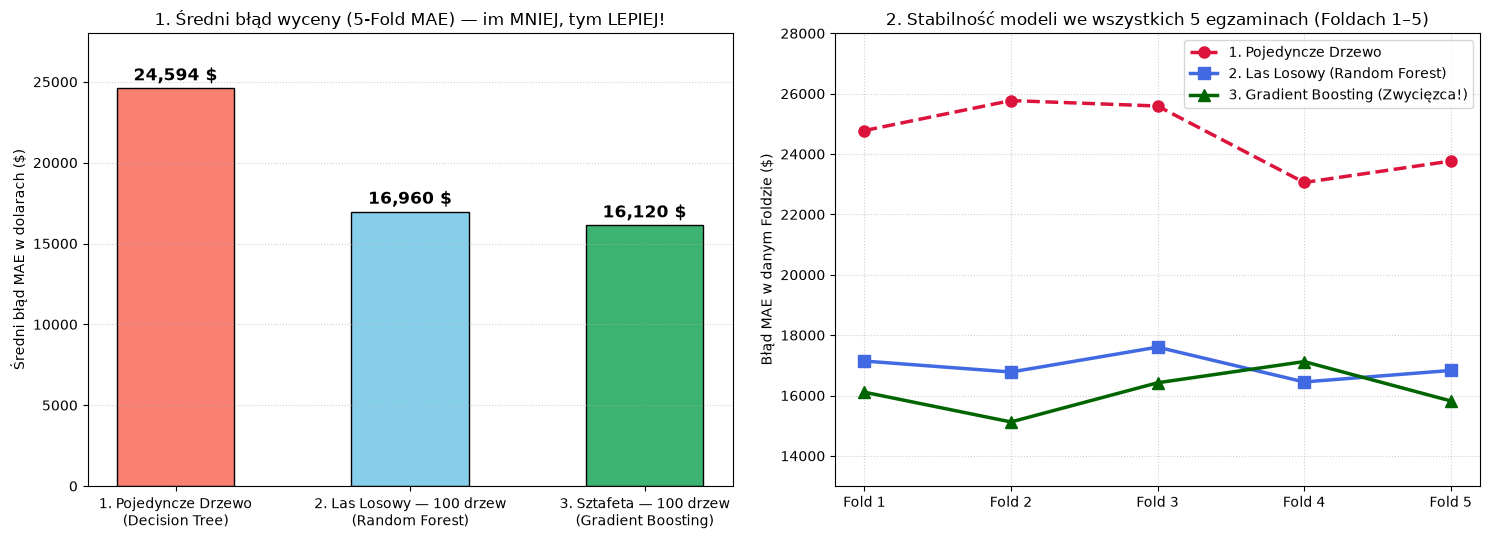

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# 1. Wczytujemy dane z folderu ../data/ i wykonujemy nasze wszystkie najlepsze kroki z Lekcji 1–8:
train = pd.read_csv('../data/train.csv')

# A) Usuwamy 2 ekstremalne anomalie odkryte na wykresie w Lekcji 2 i 7
train = train[~((train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000))].copy()

# B) Kodujemy porządkowo (Ordinal Encoding) 4 cechy jakościowe z Lekcji 6
mapa_jakosci = {'Brak': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
for kol in ['KitchenQual', 'ExterQual', 'BsmtQual', 'FireplaceQu']:
    train[kol + '_Num'] = train[kol].fillna('Brak').map(mapa_jakosci)

# C) Tworzymy nasze 4 autorskie cechy (Feature Engineering) z Lekcji 8
train['TotalSF'] = train['TotalBsmtSF'] + train['1stFlrSF'] + train['2ndFlrSF']
train['TotalBath'] = train['FullBath'] + (0.5 * train['HalfBath']) + train['BsmtFullBath'] + (0.5 * train['BsmtHalfBath'])
train['HouseAge'] = train['YrSold'] - train['YearBuilt']
train['RemodAge'] = train['YrSold'] - train['YearRemodAdd']

cechy = [
    'OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF',
    'YearBuilt', 'YearRemodAdd', 'LotArea', 'BsmtFinSF1',
    'KitchenQual_Num', 'ExterQual_Num', 'BsmtQual_Num', 'FireplaceQu_Num',
    'TotalSF', 'TotalBath', 'HouseAge', 'RemodAge'
]

X = train[cechy]
y = train['SalePrice']

# 2. Przygotowujemy naszego uczciwego sędziego (5-Fold Cross-Validation)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 3. Stawiamy na starcie naszych 3 zawodników!
zawodnicy = [
    ('1. Pojedyncze Drzewo\n(Decision Tree)', DecisionTreeRegressor(random_state=42)),
    ('2. Las Losowy — 100 drzew\n(Random Forest)', RandomForestRegressor(n_estimators=100, random_state=42)),
    ('3. Sztafeta — 100 drzew\n(Gradient Boosting)', GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42))
]

nazwy_modeli = []
srednie_mae = []
wyniki_po_foldach = {}

print('=== 🏆 WYNIKI WIELKIEGO TURNIEJU MODELI (5-FOLD CROSS-VALIDATION) ===')
for nazwa, model in zawodnicy:
    foldy = -cross_val_score(model, X, y, cv=kf, scoring='neg_mean_absolute_error')
    srednia = foldy.mean()
    nazwy_modeli.append(nazwa)
    srednie_mae.append(srednia)
    wyniki_po_foldach[nazwa] = foldy
    czysta_nazwa = nazwa.replace('\n', ' ')
    print(f'{czysta_nazwa:45s} -> Średni błąd MAE: {srednia:,.0f} $')

# 4. WIZUALIZACJA: Rysujemy dwa wykresy porównawcze obok siebie!
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Wykres lewy: Średni błąd 5-Fold CV dla każdego z 3 modeli
kolory = ['salmon', 'skyblue', 'mediumseagreen']
ax1.bar(nazwy_modeli, srednie_mae, color=kolory, edgecolor='black', width=0.5)
ax1.set_title('1. Średni błąd wyceny (5-Fold MAE) — im MNIEJ, tym LEPIEJ!')
ax1.set_ylabel('Średni błąd MAE w dolarach ($)')
ax1.set_ylim(0, 28000)
for i, v in enumerate(srednie_mae):
    ax1.text(i, v + 500, f'{v:,.0f} $', ha='center', fontweight='bold', fontsize=12)
ax1.grid(axis='y', linestyle=':', alpha=0.6)

# Wykres prawy: Jak każdy z 3 modeli radził sobie w poszczególnych 5 Foldach (egzaminach 1-5)?
numery_foldow = ['Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5']
style_linii = [('--o', 'crimson', '1. Pojedyncze Drzewo'), ('-s', 'royalblue', '2. Las Losowy (Random Forest)'), ('-^', 'darkgreen', '3. Gradient Boosting (Zwycięzca!)')]

for (nazwa, _), (styl, kolor, etykieta) in zip(zawodnicy, style_linii):
    ax2.plot(numery_foldow, wyniki_po_foldach[nazwa], styl, color=kolor, linewidth=2.5, markersize=8, label=etykieta)

ax2.set_title('2. Stabilność modeli we wszystkich 5 egzaminach (Foldach 1–5)')
ax2.set_ylabel('Błąd MAE w danym Foldzie ($)')
ax2.set_ylim(13000, 28000)
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 🎛️ Co oznaczają 3 pokrętła w `GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3)`?

Spójrz na prawy wykres powyżej: zielona linia (**Gradient Boosting**) w niemal każdym z 5 egzaminów biegnie **najniżej** (najmniejszy błąd, średnio **`16 120 $`** — to aż o **8 474 \$ lepiej** niż pojedyncze drzewo i o **840 \$ lepiej** niż Las Losowy!).

W nawiasie `GradientBoostingRegressor` ustawiliśmy 3 ważne parametry (w ML nazywamy je **hiperparametrami** — czyli pokrętłami, które ustawia człowiek przed włączeniem maszyny):

1. **`n_estimators=100` (Liczba biegaczy w sztafecie):**  
   Ile kolejnych drzewek ma poprawiać błędy swoich poprzedników.
2. **`learning_rate=0.1` (Tempo nauki / Długość kroku):**  
   Wyobraź sobie, że schodzisz ze stromego szczytu góry w gęstej mgle, szukając najniższego punktu w dolinie (najmniejszego błędu).  
   * Gdybyś robił gigantyczne skoki (`learning_rate = 1.0`), łatwo przeskoczyłbyś nad doliną i spadł w przepaść!
   * Ustawiając **`learning_rate = 0.1`**, każesz każdemu drzewku w sztafecie wykonać tylko **ostrożny kroczek o długości 10% wyliczonej poprawki**, a resztę zostawić kolejnym drzewkom. Małe kroczki (`0.05` lub `0.1`) przy dużej liczbie drzew dają najdokładniejsze modele na świecie!
3. **`max_depth=3` (Maksymalna głębokość każdego drzewka = tylko 3 piętra pytań!):**  
   * W **Lesie Losowym** każde drzewo jest wielkim ekspertem (ma 15–20 pięter głębokości).
   * W **Gradient Boostingu** każde drzewko w sztafecie ma być tzw. **„słabym uczniem” (*Weak Learner*)** — wolno mu zadać maksymalnie **3 proste pytania w dół (`max_depth=3`)**! Dlaczego? Bo 100 prostych, skromnych wskazówek dodanych po kolei tworzy genialny model, podczas gdy 100 przemądrzałych, głębokich drzew w sztafecie natychmiast przeuczyłoby się na pamięć!

---

## 🗺️ Twoja Osobista Mapa Drogowa (Check-lista 7 Kroków na każdy kolejny konkurs Kaggle!)

Od dziś masz w ręku kompletny warsztat początkującego Data Scientista. Niezależnie od tego, czy Twój kolejny projekt na Kaggle będzie dotyczył **przeżywalności pasażerów Titanica**, **cen używanych samochodów**, czy **prognozowania sprzedaży w sklepach**, **ZAAWSZE postępuj według tej samej 7-punktowej listy kontrolnej**:

### ✅ KROK 1: Zwiad terenu (`Lekcja 1`)
* Wczytaj pliki `pd.read_csv('../data/train.csv')` oraz `pd.read_csv('../data/test.csv')`.
* Sprawdź ich wymiary (`.shape`), pierwsze wiersze (`.head()`) oraz przeczytaj opis kolumn.
* Zbadaj kolumnę docelową (`.describe()` + histogram `plt.hist()`): sprawdź, czy nie jest mocno przekrzywiona (średnia daleka od mediany).

### ✅ KROK 2: Wizualizacja i łowienie anomalii (`Lekcja 2`)
* Jeśli cel (np. cena) ma długi ogon w prawo, sprawdź jego logarytm (`np.log1p()`, a na końcu odwracaj przez `np.expm1()`).
* Narysuj wykresy punktowe (`plt.scatter`) i pudełkowe (`.boxplot()`) dla najważniejszych cech.
* Jeśli zobaczysz oczywiste anomalie (*Outliery* w zbiorze `train`, które psują trend), odfiltruj je przed treningiem!

### ✅ KROK 3: Wielkie sprzątanie braków `NaN` (`Lekcja 3`)
* Policz braki w **obu** tabelach (`train.isnull().sum()` oraz `test.isnull().sum()`).
* Odróżnij **pozorny brak** (np. `NaN` = brak basenu/garażu $\rightarrow$ wpisz `'Brak'` lub `0`) od **prawdziwej dziury w danych** (uzupełnij liczby **medianą `.median()`**, a tekst **dominantą `.mode()[0]`**).

### ✅ KROK 4: Szybki model bazowy (*Baseline*) i pierwszy `submission.csv` (`Lekcja 4 i 5`)
* Nie czekaj do końca projektu z pierwszym modelem! Wybierz 5–8 najprostszych kolumn liczbowych, wytrenuj `RandomForestRegressor` i wygeneruj swój pierwszy plik `.to_csv('submission.csv', index=False)`.
* Zrób wykres kontrolny rozkładu predykcji. Od tej chwili masz swój **punkt odniesienia (*Baseline*)**, który w kolejnych krokach będziesz pobijać!

### ✅ KROK 5: Uczciwy sędzia — Walidacja Krzyżowa `K-Fold` (`Lekcja 7`)
* Ustaw `kf = KFold(n_splits=5, shuffle=True, random_state=42)` i oceniaj każdy swój nowy pomysł za pomocą średniej z 5 foldów (`cross_val_score`), a nie pojedynczego losowania.

### ✅ KROK 6: Kodowanie tekstu i Inżynieria Cech (`Lekcja 6 i 8`)
* Zamień słowa z naturalną drabiną jakości na liczby `0..5` (**Ordinal Encoding** przez `.map(slownik)`).
* Zamień słowa bez drabiny (dzielnice, typy) na przełączniki `0/1` (**One-Hot Encoding** przez `pd.get_dummies(..., dtype=int)`).
* Twórz własne cechy z wiedzy o świecie (**Feature Engineering**: sumy powierzchni, wiek, stosunki) i po każdej nowej cesze sprawdzaj, czy wynik `5-Fold CV` się poprawił!

### ✅ KROK 7: Turniej modeli i finałowa wysyłka (`Lekcja 9`)
* Porównaj na gotowych danych `RandomForestRegressor` oraz `GradientBoostingRegressor` (a w przyszłości też `XGBoost` / `LightGBM`).
* Wybierz zwycięzcę (albo uśrednij wyceny dwóch najlepszych modeli!), wytrenuj go na 100% danych treningowych i wyślij finałowy plik na Kaggle!

In [2]:
# 🎯 FINAŁOWE ĆWICZENIE KURSU: Połączmy naszego zwycięzcę (Gradient Boosting) z logarytmowaniem cen (np.log1p)
# i wygenerujmy Twój najlepszy plik `submission_final.csv`!

# Przygotowujemy dokładnie te same 16 cech w tabeli `test.csv`:
test = pd.read_csv('../data/test.csv')

for kol in ['KitchenQual', 'ExterQual', 'BsmtQual', 'FireplaceQu']:
    test[kol + '_Num'] = test[kol].fillna('Brak').map(mapa_jakosci)

kolumny_do_sum = ['TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'FullBath', 'HalfBath', 'BsmtFullBath', 'BsmtHalfBath', 'GarageCars', 'BsmtFinSF1']
for kol in kolumny_do_sum:
    test[kol] = test[kol].fillna(0)

test['TotalSF'] = test['TotalBsmtSF'] + test['1stFlrSF'] + test['2ndFlrSF']
test['TotalBath'] = test['FullBath'] + (0.5 * test['HalfBath']) + test['BsmtFullBath'] + (0.5 * test['BsmtHalfBath'])
test['HouseAge'] = test['YrSold'] - test['YearBuilt']
test['RemodAge'] = test['YrSold'] - test['YearRemodAdd']

X_test_final = test[cechy].fillna(0)

# 1. Stwórz model `zwyciezca = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)`
# 2. Wytrenuj model `zwyciezca` metodą .fit() na `X` oraz zlogarytmowanym `y`: zwyciezca.fit(X, np.log1p(y))
# 3. Przewidź ceny dla `X_test_final` i odwróć logarytm przez np.expm1(): ceny_finalne = np.expm1(zwyciezca.predict(X_test_final))
# 4. Zapisz plik `submission_final.csv` z parametrem index=False i wyświetl pierwsze 5 wierszy!

# Miejsce na Twój kod:


---
### 📌 Podsumowanie lekcji w 3 punktach

1. **Trzy sposoby uczenia drzew:** Pojedyncze Drzewo (`DecisionTreeRegressor`, błąd `24 594 $`) łatwo przeucza się na pamięć; Las Losowy (`RandomForestRegressor`, błąd `16 960 $`) uśrednia głosy 100 niezależnych drzew (*Bagging*); natomiast Gradient Boosting (`GradientBoostingRegressor`, błąd `16 120 $`) buduje sztafetę płytkich drzewek (*Boosting*), w której każde kolejne drzewko uczy się naprawiać błędy poprzedników.
2. **Trzy główne hiperparametry Gradient Boostingu:** `n_estimators=100` określa liczbę drzewek w sztafecie, `learning_rate=0.1` nakazuje robić małe, ostrożne kroczki przy każdej korekcie, a `max_depth=3` ogranicza głębokość pojedynczego drzewka do 3 pięter pytań, chroniąc model przed przeuczeniem.
3. **Uniwersalny schemat projektu ML (7 Kroków):** Zwiad danych $\rightarrow$ Wizualizacja i usunięcie anomalii $\rightarrow$ Łatanie braków `NaN` $\rightarrow$ Szybki model bazowy (*Baseline*) $\rightarrow$ Walidacja `5-Fold CV` $\rightarrow$ Kodowanie tekstu i *Feature Engineering* $\rightarrow$ Turniej modeli i wysyłka `submission.csv`.